# Unit Search with Dense Units: Sparse Target Network

Can unit search find the structure of a deep, sparsely connected target network when every new unit reads
everything below it and feeds everything above it, and connection pruning removes the connections that do not matter?

**Problem.** Each sample has $N = 1000$ standard normal inputs. The targets are the 100 outputs of a fixed target network
plus $N(0, 0.1^2)$ noise, so the best possible RMSE is 0.1 (dotted line in the plots). The target network has 3 hidden
layers of 20 LTUs. Each hidden unit reads 10 distinct units of lower depths (the inputs being depth 0), each picked by
choosing a lower depth uniformly and then a unit of that depth; each output does the same over the hidden depths only.
Weights are $N(0, 1)$, each hidden unit's threshold makes it fire 30% of the time, and each output is scaled to zero mean
and unit variance, so predicting 0 gives an RMSE of about 1. The target network is the same for every seed. A linear
fit on the inputs explains about 62% of the targets' variance.

**Learner.** Hidden units are LTUs (sigmoid derivative backward) at depths 1 to 3; a unit reads inputs and units of
lower depths, and the outputs (depth 4) read hidden units. The loss is half the summed squared error.
Network Autostep: Autostep (`squared_inputs`, initial step-size $10^{-5}$, meta step-size 0.01,
  $\tau = 10^4$); hidden units standardized online, $h = (b - m)/\sqrt{\max(m(1 - m), 0.01)}$, with the backward pass
  through the statistics as in `unit_search/parallel_mnist_label_changes.ipynb`; hidden-unit weights start
  $U(-10^{-5}, 10^{-5})$, output weights and biases at 0.

**Runs.** 300k steps, 5 seeds (1 per configuration in the unit search grid), every value averaged over each of 100
windows; final performance is the RMSE over the last 10% of training.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS, N_OUTPUTS = 1000, 100
TEACHER_WIDTH = 20                   # target units per hidden layer, at depths 1-3
TEACHER_FAN_IN = 10                  # each target unit and output reads this many units of lower depths
FIRING_RATE = 0.3                    # each target hidden unit's threshold makes it fire this often
NOISE_STD = 0.1                      # observation noise on every target: the RMSE floor

# --- Network and learner ---
N_DEPTHS = 3                         # hidden depths; outputs are at depth N_DEPTHS + 1
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of hidden units
INIT_STEP_SIZE = 1e-5                # Autostep's initial step-size, also the scale of initial hidden-unit weights
META_STEP_SIZE, TAU = 0.01, 1e4

# --- Training ---
N_SEEDS = 5
NUM_STEPS = 300_000
N_WINDOWS = 100                      # each window records the mean of every recorded value
RUNS_PER_BATCH = 40                  # runs vmapped together
FINAL_FRACTION = 0.1                 # final performance: the last 10% of training

# --- Unit search ---
START_UNITS = 30                     # units per depth made by the first structure change
SLOTS_PER_DEPTH = 30                 # the most units a depth can have
DEPTH_BUDGET = tuple(START_UNITS * (N_INPUTS + 1 + START_UNITS * d) for d in range(N_DEPTHS))
                                     # 30,030 / 30,930 / 31,830: incoming connections and biases of each depth's units,
                                     # as many as 30 units reading every input and 30 units of each lower depth
BASE_PERIOD = 1000                   # steps between checks for a due structure change
PRUNE_EVERY = (3_000, 10_000, 30_000, 100_000)   # steps between structure changes
PRUNE_FRACTIONS = (0.05, 0.1, 0.3, 0.5)          # of each depth's units, pruned at each structure change
NEW_UNITS = True                     # whether structure changes after the first make new units

## Target network

In [3]:
def make_teacher(key, n_samples=20_000):
    # A sparse LTU network. Each hidden unit, at depth d, reads TEACHER_FAN_IN distinct units of lower depths, each
    # picked by choosing a lower depth uniformly (depth 0 being the inputs) and then a unit of that depth; each output
    # does the same over hidden depths only. Weights are N(0, 1), each hidden unit's threshold makes it fire
    # FIRING_RATE of the time, and each output is scaled to zero mean and unit variance. Units are stored by depth:
    # sources are [inputs, hidden units], hidden unit u of depth d being slot (d - 1) * TEACHER_WIDTH + u.
    n_hidden = N_DEPTHS * TEACHER_WIDTH
    depth = jnp.repeat(jnp.arange(1, N_DEPTHS + 1), TEACHER_WIDTH)
    source_depth = jnp.concatenate([jnp.zeros(N_INPUTS, int), depth])
    group_size = jnp.array([N_INPUTS] + [TEACHER_WIDTH] * N_DEPTHS)

    def pick(key, allowed):
        # TEACHER_FAN_IN distinct sources: a uniformly chosen allowed depth, then a uniformly chosen unit in it
        # (Gumbel top-k, which samples without replacement in proportion to these probabilities).
        p = jnp.where(allowed[source_depth], 1.0 / group_size[source_depth], 0.0)
        gumbel = jax.random.gumbel(key, p.shape)
        top = jax.lax.top_k(jnp.where(p > 0, jnp.log(p) + gumbel, -jnp.inf), TEACHER_FAN_IN)[1]
        return jnp.zeros(p.shape, bool).at[top].set(True)

    keys = jax.random.split(key, 4)
    lower = jnp.arange(N_DEPTHS + 1)[None, :] < depth[:, None]                    # (unit, depth) allowed sources
    hidden_mask = jax.vmap(pick)(jax.random.split(keys[0], n_hidden), lower)
    output_allowed = (jnp.arange(N_DEPTHS + 1) > 0)
    output_mask = jax.vmap(lambda k: pick(k, output_allowed))(jax.random.split(keys[1], N_OUTPUTS))[:, N_INPUTS:]
    hidden_w = jax.random.normal(keys[2], hidden_mask.shape) * hidden_mask
    output_w = jax.random.normal(keys[3], output_mask.shape) * output_mask

    # Thresholds, depth by depth, from a batch of inputs.
    x = jax.random.normal(jax.random.fold_in(key, 1), (n_samples, N_INPUTS))
    bits = jnp.zeros((n_samples, n_hidden))
    threshold = jnp.zeros(n_hidden)
    for d in range(1, N_DEPTHS + 1):
        z = jnp.concatenate([x, bits], axis=1) @ hidden_w.T
        threshold = jnp.where(depth == d, jnp.quantile(z, 1 - FIRING_RATE, axis=0), threshold)
        bits = jnp.where(depth == d, (z > threshold).astype(jnp.float32), bits)
    raw = bits @ output_w.T
    return {'hidden_w': hidden_w, 'threshold': threshold, 'depth': depth, 'output_w': output_w,
            'output_mean': raw.mean(0), 'output_std': raw.std(0)}


def teacher_targets(teacher, x):
    bits = jnp.zeros(N_DEPTHS * TEACHER_WIDTH)
    for d in range(1, N_DEPTHS + 1):
        z = teacher['hidden_w'] @ jnp.concatenate([x, bits])
        bits = jnp.where(teacher['depth'] == d, (z > teacher['threshold']).astype(jnp.float32), bits)
    return (teacher['output_w'] @ bits - teacher['output_mean']) / teacher['output_std']


TEACHER = make_teacher(jax.random.PRNGKey(123))


def next_sample(key):
    # One sample: standard normal inputs, and the target network's outputs plus N(0, NOISE_STD^2) noise.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, teacher_targets(TEACHER, x) + NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped like the hidden units.
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


def init_stats(shape):
    return Stats(jnp.full(shape, 0.5), jnp.zeros(shape), jnp.zeros(shape))


def hidden_values(bits, stats, autostep):
    # What a hidden unit sends: its standardized bit with network Autostep (statistics moved toward this sample
    # first), the bit itself with SGD. Returns the values and the moved firing rates.
    if not autostep:
        return bits, stats.hidden_mean
    mean = stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(bits) - stats.hidden_mean)
    return standardize(bits, mean, stats.error_mean, stats.error_h_mean), mean


def update(w, opt, stats, grads, sources, error, h, hidden_mean, autostep, step_size):
    # Network Autostep, or SGD at `step_size`, on the weights; the hidden units' statistics move toward this sample.
    # Returns the new weights, optimizer state and statistics.
    if not autostep:
        return jax.tree.map(lambda w, g: w - step_size * g, w, grads), opt, stats
    updates, opt = OPTIMIZER.update((grads, None, sources), opt, w)
    stats = Stats(hidden_mean, stats.error_mean + STAT_RATE * (error - stats.error_mean),
                  stats.error_h_mean + STAT_RATE * (error * h - stats.error_h_mean))
    return jax.tree.map(jnp.add, w, updates), opt, stats


def lecun(key, shape, fan_in):
    return jax.random.uniform(key, shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / fan_in)


# --- Fully connected networks: one weight matrix per layer, the last column the bias ---
LAYERS = [f'layer {d}' for d in range(1, N_DEPTHS + 1)] + ['output']


class Dense(NamedTuple):
    w: dict                     # LAYERS -> (units, units below + 1)
    opt: IDBDState
    stats: Stats                # each (N_DEPTHS, width)


def init_dense(key, width, autostep):
    # Network Autostep: hidden weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE), output weights 0, biases 0. SGD: LeCun
    # uniform weights, biases 0.
    shapes = [(width, N_INPUTS + 1)] + [(width, width + 1)] * (N_DEPTHS - 1) + [(N_OUTPUTS, width + 1)]
    keys = jax.random.split(key, len(LAYERS))
    if autostep:
        w = {k: jax.random.uniform(key, shape, minval=-INIT_STEP_SIZE, maxval=INIT_STEP_SIZE)
             for k, key, shape in zip(LAYERS[:-1], keys, shapes)}
        w['output'] = jnp.zeros(shapes[-1])
    else:
        w = {k: lecun(key, shape, shape[1]) for k, key, shape in zip(LAYERS, keys, shapes)}
    w = {k: v.at[:, -1].set(0.0) for k, v in w.items()}
    return Dense(w, OPTIMIZER.init(w), init_stats((N_DEPTHS, width)))


def learn_dense(net, x, y, autostep, step_size):
    # One online update on half the summed squared error. Returns the new network and the mean squared error over the
    # outputs on this sample, before learning from it. `probe` is zero; its gradient is the error arriving at each
    # hidden unit.
    def loss_fn(w, probe):
        a, sources, means, hs = x, {}, [], []
        for d, k in enumerate(LAYERS[:-1]):
            source = jnp.append(a, 1.0)
            sources[k] = jnp.broadcast_to(jax.lax.stop_gradient(source), w[k].shape)
            h, mean = hidden_values(ltu(w[k] @ source), jax.tree.map(lambda s: s[d], net.stats), autostep)
            a = h + probe[d]
            means.append(mean)
            hs.append(jax.lax.stop_gradient(h))
        source = jnp.append(a, 1.0)
        sources['output'] = jnp.broadcast_to(jax.lax.stop_gradient(source), w['output'].shape)
        return 0.5 * jnp.sum((w['output'] @ source - y) ** 2), (sources, jnp.stack(hs), jnp.stack(means))

    probe = jnp.zeros(net.stats.hidden_mean.shape)
    (loss, (sources, h, hidden_mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, probe)
    w, opt, stats = update(net.w, net.opt, net.stats, grads, sources, error, h, hidden_mean, autostep, step_size)
    return Dense(w, opt, stats), 2 * loss / N_OUTPUTS


# --- Masked networks: a block of unit slots per depth, every possible connection a weight with a mask ---
class Masked(NamedTuple):
    # Hidden units sit in slots, a block of equal size per depth (depth 1 first); `alive` marks the slots that hold a
    # unit. Hidden unit u's weights are row u of w['hidden'], over the sources [inputs, hidden slots, 1 (the bias)];
    # the outputs' weights are w['output'], over [hidden slots, 1]. `mask` says which connections exist.
    w: dict                     # {'hidden': (slot, N_INPUTS + slot + 1), 'output': (output, slot + 1)}
    mask: dict                  # shaped like w
    alive: jax.Array            # (slot,)
    opt: IDBDState
    stats: Stats                # each (slot,)


def learn_masked(net, x, y, feedback=None, l1=0.0):
    # One online network-Autostep update on half the summed squared error, with L1 regularization (its subgradient,
    # for every existing weight but the biases, added to the gradient Autostep learns from). Hidden units are computed
    # depth by depth. `feedback`, if given, replaces the output weights in the backward pass only (shadow weights).
    # Returns the new network and the mean squared error over the outputs on this sample, before learning from it.
    # `probe` is zero; its gradient is the error arriving at each hidden unit.
    n = len(net.alive)
    block = n // N_DEPTHS
    back = None if feedback is None else jax.lax.stop_gradient(feedback)

    def loss_fn(w, probe):
        w = {k: w[k] * net.mask[k] for k in w}
        a, bits = jnp.zeros(n), []
        for d in range(N_DEPTHS):
            rows = slice(d * block, (d + 1) * block)
            b = ltu(w['hidden'][rows] @ jnp.concatenate([x, a, jnp.ones(1)]))
            h, _ = hidden_values(b, jax.tree.map(lambda s: s[rows], net.stats), True)
            a = a.at[rows].set(jnp.where(net.alive[rows], h + probe[rows], 0.0))
            bits.append(jax.lax.stop_gradient(b))
        source = jnp.append(a, 1.0)
        if back is None:
            prediction = w['output'] @ source
        else:
            through_back = back[:, :-1] @ a
            prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                          - jax.lax.stop_gradient(through_back))
        values = jax.lax.stop_gradient(jnp.concatenate([x, source]))
        sources = {'hidden': jnp.broadcast_to(values, w['hidden'].shape) * net.mask['hidden'],
                   'output': jnp.broadcast_to(values[N_INPUTS:], w['output'].shape) * net.mask['output']}
        return 0.5 * jnp.sum((prediction - y) ** 2), (sources, jax.lax.stop_gradient(a), jnp.concatenate(bits))

    (loss, (sources, h, bits)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, jnp.zeros(n))
    grads = {k: (grads[k] + l1 * jnp.sign(net.w[k]).at[:, -1].set(0.0)) * net.mask[k] for k in grads}
    hidden_mean = net.stats.hidden_mean + STAT_RATE * (bits - net.stats.hidden_mean)
    w, opt, stats = update(net.w, net.opt, net.stats, grads, sources, error, h, hidden_mean, True, None)
    return net._replace(w=w, opt=opt, stats=stats), 2 * loss / N_OUTPUTS


def init_masked(key, mask, alive):
    # Hidden-unit weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE), output weights 0, biases 0.
    w_hidden = jax.random.uniform(key, mask['hidden'].shape, minval=-INIT_STEP_SIZE, maxval=INIT_STEP_SIZE)
    w = {'hidden': w_hidden.at[:, -1].set(0.0) * mask['hidden'], 'output': jnp.zeros(mask['output'].shape)}
    return Masked(w, mask, alive, OPTIMIZER.init(w), init_stats(len(alive)))

## Unit search

The network has 30 unit slots per depth. Each depth has a budget for its units' incoming connections and biases: as
many as 30 units would hold reading every input and 30 units of each lower depth, $30 (1001 + 30 (d - 1))$, so 30,030,
30,930 and 31,830 for depths 1 to 3. The outputs' connections are not budgeted.

Every step, a connection is marked for pruning if its weight crosses zero while its step-size is below half its
initial value; biases are never marked.

Every $n$ steps, starting at step 0:
1. *Connection pruning.* The marked connections are cut, and the marks cleared.
2. *Dead units.* A unit left with no inputs or no outgoing connections is removed.
3. *Unit pruning.* At each depth, the fraction $x$ of its units (rounded) with the smallest summed |outgoing weight|
   are pruned, with their connections.
4. *Generation.* Depth by depth from depth 1, new units fill the depth's free budget, as far as its free slots allow.
   Each reads every input and every unit of lower depths, and feeds every output and every unit of higher depths,
   among the units that existed before this structure change. The connections into units of higher depths count
   against the consumer's depth and are made, as far as its budget allows (the first new units' first), before that
   depth's new units. One of a new unit's output connections, chosen at random, carries a fixed $\pm 1$ shadow weight:
   in the backward pass only, it stands in for the real weight unless the real one is larger in magnitude or the
   connection is gone. Input weights start $U(-10^{-5}, 10^{-5})$, the bias and outgoing weights at 0, and their
   step-sizes at $10^{-5}$.

The first structure change, at step 0, makes 30 units per depth, which therefore read only the inputs and feed only the
outputs.

**Runs.** 300k steps, no L1 anywhere. Unit search without connection pruning (step 1 skipped), 1 seed per
configuration: $n$ = 3k, 10k, 30k and 100k steps, each with $x$ = 5%, 10%, 30% and 50%. *Starting network* (baseline,
5 seeds): the first structure change, with nothing cut or pruned afterwards. *Target wiring* (reference, 5 seeds): the
target network's own connectivity and depths, learned weights, no shadow weights. *Fully connected 3 × 30* (reference,
5 seeds): each layer reads only the one below, about 35k connections. All use network Autostep; unit search and the starting
network use shadow weights.

In [5]:
class Config(NamedTuple):
    prune_every: int            # steps between structure changes
    prune_fraction: float       # of each depth's units, pruned for low utility at each structure change
    l1: float                   # L1 regularization
    prune_connections: bool     # whether marked connections are cut


class Search(NamedTuple):
    marked: dict                # connections to cut at the next structure change, shaped like w
    shadow: jax.Array           # shaped like w['output']: the +-1 shadow weight on each unit's paired output, else 0


def empty_network(key):
    # No hidden units yet: only the output biases exist.
    n = N_DEPTHS * SLOTS_PER_DEPTH
    mask = {'hidden': jnp.zeros((n, N_INPUTS + n + 1), bool),
            'output': jnp.zeros((N_OUTPUTS, n + 1), bool).at[:, -1].set(True)}
    return init_masked(key, mask, jnp.zeros(n, bool))


def teacher_network(key):
    # The target network's own wiring, in blocks of TEACHER_WIDTH slots per depth (its sources are already indexed as
    # inputs, then its hidden units by depth).
    ones = lambda rows: jnp.ones((rows, 1), bool)
    mask = {'hidden': jnp.append(TEACHER['hidden_w'] != 0, ones(N_DEPTHS * TEACHER_WIDTH), axis=1),
            'output': jnp.append(TEACHER['output_w'] != 0, ones(N_OUTPUTS), axis=1)}
    return init_masked(key, mask, jnp.ones(N_DEPTHS * TEACHER_WIDTH, bool))


def init_search(net):
    return Search(jax.tree.map(lambda m: jnp.zeros(m.shape, bool), net.mask), jnp.zeros(net.w['output'].shape))


def shadow_feedback(net, search):
    # The output weights the backward pass uses: each unit's paired output weight is replaced by its shadow weight
    # unless the real one is larger in magnitude.
    w = net.w['output']
    return jnp.where((search.shadow != 0) & (jnp.abs(w) < 1.0), search.shadow, w) * net.mask['output']


def per_unit(mask, value):
    # Each slot's sum of `value` (shaped like the weights) over its outgoing connections, those that `mask` keeps.
    n = mask['output'].shape[1] - 1
    return (jnp.sum(jnp.where(mask['hidden'], value['hidden'], 0.0), axis=0)[N_INPUTS:N_INPUTS + n]
            + jnp.sum(jnp.where(mask['output'], value['output'], 0.0), axis=0)[:n])


def restructure(net, search, config, key, first):
    # A structure change; `first` marks the first fill. Returns the new network and search state, the number of units removed, and the number of
    # connections cut by connection pruning.
    n, block = len(net.alive), SLOTS_PER_DEPTH
    slot_depth = jnp.arange(n) // block + 1
    budget = jnp.array(DEPTH_BUDGET)
    w, mask, alive = dict(net.w), dict(net.mask), net.alive

    # 1. Marked connections are cut (biases are never marked).
    cut = {k: search.marked[k] & mask[k] & config.prune_connections for k in mask}
    mask = {k: mask[k] & ~cut[k] for k in mask}

    # 2. Units left with no inputs or no outgoing connections are removed. 3. At each depth, the prune fraction of its
    # units (rounded) with the smallest summed |outgoing weight| are pruned. A removed unit's connections go with it.
    dead = alive & ((mask['hidden'][:, :-1].sum(1) == 0) | (per_unit(mask, jax.tree.map(jnp.ones_like, w)) == 0))
    utility = per_unit(mask, jax.tree.map(jnp.abs, w))
    eligible = alive & ~dead
    removed = dead
    for d in range(N_DEPTHS):
        rows = slice(d * block, (d + 1) * block)
        rank = jnp.argsort(jnp.argsort(jnp.where(eligible[rows], utility[rows], jnp.inf)))
        pruned = eligible[rows] & (rank < jnp.round(config.prune_fraction * alive[rows].sum()))
        removed = removed.at[rows].set(removed[rows] | pruned)
    as_source = jnp.append(removed, False)
    mask = {'hidden': mask['hidden'] & ~removed[:, None] & ~jnp.append(jnp.zeros(N_INPUTS, bool), as_source)[None],
            'output': mask['output'] & ~as_source[None]}
    shadow = jnp.where(mask['output'], search.shadow, 0.0)
    alive = alive & ~removed

    # 4. Generation, depth by depth from depth 1. New units fill the depth's free budget (its units' incoming
    # connections and biases), as far as its free slots allow. Each reads every input and every existing unit of lower
    # depths, and feeds every output, one of them, chosen at random, carrying a fixed +-1 shadow weight, and every
    # existing unit of higher depths, as far as the consumer's depth has budget left (the first new units' first).
    # These count against the consumer's depth, before that depth's new units are made. Existing units: those from
    # before this structure change. Input weights start U(-INIT_STEP_SIZE, INIT_STEP_SIZE), the bias and outgoing
    # weights at 0, their step-sizes at INIT_STEP_SIZE with Autostep's traces at 0, and the unit's statistics as at the
    # start. After the first fill, new units are made only if NEW_UNITS.
    existing = alive
    new_all = jnp.zeros(n, bool)
    changed = jax.tree.map(lambda m: jnp.zeros(m.shape, bool), mask)
    for d, depth_key in enumerate(jax.random.split(key, N_DEPTHS)):
        rows = slice(d * block, (d + 1) * block)
        pair_key, sign_key, weight_key = jax.random.split(depth_key, 3)
        reads = jnp.concatenate([jnp.ones(N_INPUTS, bool), existing & (slot_depth <= d), jnp.ones(1, bool)])
        free_slots = ~alive[rows]
        count = jnp.minimum((budget[d] - mask['hidden'][rows].sum()) // reads.sum(), free_slots.sum())
        count = jnp.where(first | NEW_UNITS, count, 0)
        new = free_slots & (jnp.cumsum(free_slots) <= count)
        row_w = jax.random.uniform(weight_key, (block, len(reads)), minval=-INIT_STEP_SIZE, maxval=INIT_STEP_SIZE)
        mask['hidden'] = mask['hidden'].at[rows].set(jnp.where(new[:, None], reads[None], mask['hidden'][rows]))
        w['hidden'] = w['hidden'].at[rows].set(jnp.where(new[:, None], (row_w * reads).at[:, -1].set(0.0),
                                                         w['hidden'][rows]))
        changed['hidden'] = changed['hidden'].at[rows].set(changed['hidden'][rows] | new[:, None])

        column = jnp.append(jnp.zeros(n, bool).at[rows].set(new), False)[None]
        mask['output'], changed['output'] = mask['output'] | column, changed['output'] | column
        w['output'] = jnp.where(column, 0.0, w['output'])
        paired = jnp.arange(N_OUTPUTS)[:, None] == jax.random.randint(pair_key, (block,), 0, N_OUTPUTS)[None]
        sign = jax.random.rademacher(sign_key, (block,), dtype=jnp.float32)
        shadow = shadow.at[:, rows].set(jnp.where(new[None], paired * sign[None], shadow[:, rows]))

        used = jnp.zeros(N_DEPTHS + 1).at[slot_depth].add(mask['hidden'].sum(1))[1:]   # by each depth
        feeds = new[:, None] & (existing & (slot_depth > d + 1))[None]                   # (new unit, consumer)
        for e in range(d + 1, N_DEPTHS):
            into = feeds & (slot_depth == e + 1)[None]
            feeds = feeds & ~(into & (jnp.cumsum(into.reshape(-1)).reshape(into.shape) > budget[e] - used[e]))
        into_consumers = jnp.zeros(mask['hidden'].shape, bool).at[:, N_INPUTS + d * block:N_INPUTS + (d + 1) * block].set(
            feeds.T)
        mask['hidden'], changed['hidden'] = mask['hidden'] | into_consumers, changed['hidden'] | into_consumers
        w['hidden'] = jnp.where(into_consumers, 0.0, w['hidden'])
        alive = alive.at[rows].set(alive[rows] | new)
        new_all = new_all.at[rows].set(new)

    opt = net.opt
    reset = lambda tree, value: {k: jnp.where(changed[k], value, tree[k]) for k in tree}
    net = net._replace(
        w=w, mask=mask, alive=alive,
        opt=opt._replace(beta=reset(opt.beta, jnp.log(INIT_STEP_SIZE)), h=reset(opt.h, 0.0), v=reset(opt.v, 0.0)),
        stats=Stats(*(jnp.where(new_all, value, s) for s, value in zip(net.stats, (0.5, 0.0, 0.0)))))
    return net, Search(jax.tree.map(jnp.zeros_like, search.marked), shadow), removed.sum(), sum(
        v.sum() for v in cut.values())

## Training

In [6]:
def train_dense(net, key, autostep, step_size, num_steps):
    # num_steps online steps in N_WINDOWS windows; records each window's mean squared error.
    def one_step(net, key):
        return learn_dense(net, *next_sample(key), autostep, step_size)

    def window(net, key):
        net, mse = jax.lax.scan(one_step, net, jax.random.split(key, num_steps // N_WINDOWS))
        return net, mse.mean()

    return jax.lax.scan(window, net, jax.random.split(key, N_WINDOWS))[1]


def run_dense(width, autostep, step_sizes, num_steps):
    # A fully connected network of `width` units per layer, at every step size on every seed, vmapped. Seed s gives
    # every run the same initial weights and samples. Returns the windows' RMSE, shaped (step size, seed, window).
    keys = lambda seed: jnp.tile(jax.random.split(jax.random.PRNGKey(seed), N_SEEDS), (len(step_sizes), 1))
    sizes = jnp.repeat(jnp.array(step_sizes, jnp.float32), N_SEEDS)
    nets = jax.vmap(lambda k: init_dense(k, width, autostep))(keys(0))
    started = perf_counter()
    mse = jax.jit(jax.vmap(lambda net, k, s: train_dense(net, k, autostep, s, num_steps)))(nets, keys(1), sizes)
    print(f'{len(step_sizes) * N_SEEDS} runs in {perf_counter() - started:.0f}s')
    return np.sqrt(np.asarray(mse).reshape(len(step_sizes), N_SEEDS, N_WINDOWS))


def train_search(net, search, key, config, num_steps, fixed):
    # num_steps online network-Autostep steps. Every BASE_PERIOD steps comes a structure change if one is due (every
    # prune_every steps from step 0, whose structure change is the first fill), unless the network is fixed, which also
    # has no shadow weights. Every step, connections whose weight crosses zero while their step-size is below half its
    # initial value are marked for pruning. Returns every recorded value averaged over each window.
    def one_step(carry, key):
        net, search = carry
        new, mse = learn_masked(net, *next_sample(key), None if fixed else shadow_feedback(net, search), config.l1)
        if not fixed:
            search = search._replace(marked={
                k: search.marked[k] | ((net.w[k] * new.w[k] < 0) & (jnp.exp(new.opt.beta[k]) < INIT_STEP_SIZE / 2)
                                       & net.mask[k]).at[:, -1].set(False) for k in new.w})
        return (new, search), mse

    def period(carry, inputs):
        step, key = inputs
        restructure_key, step_key = jax.random.split(key)
        units_before = carry[0].alive.sum()
        removed = cut = 0
        if not fixed:
            changed = restructure(*carry, config, restructure_key, step == 0)
            due = step % config.prune_every == 0
            *carry, removed, cut = jax.tree.map(lambda a, b: jnp.where(due, a, b), changed, (*carry, 0, 0))
        (net, search), mse = jax.lax.scan(one_step, tuple(carry), jax.random.split(step_key, BASE_PERIOD))
        units = net.alive.reshape(N_DEPTHS, -1).sum(1)
        record = {'mse': mse.mean(), 'units': units.sum(), 'removed': removed / BASE_PERIOD,
                  'cut per unit': cut / jnp.maximum(units_before, 1) / BASE_PERIOD,
                  'budgeted connections': net.mask['hidden'].sum(),
                  **{f'connections into depth {d + 1}': c for d, c in enumerate(
                      net.mask['hidden'][:, :-1].reshape(N_DEPTHS, -1, net.mask['hidden'].shape[1] - 1).sum((1, 2)))},
                  'connections into outputs': net.mask['output'][:, :-1].sum()}
        return (net, search), jax.tree.map(lambda v: jnp.asarray(v, jnp.float32), record)

    periods = num_steps // N_WINDOWS // BASE_PERIOD

    def window(carry, inputs):
        index, key = inputs
        steps = (index * periods + jnp.arange(periods)) * BASE_PERIOD
        carry, records = jax.lax.scan(period, carry, (steps, jax.random.split(key, periods)))
        return carry, jax.tree.map(lambda r: r.mean(0), records)

    return jax.lax.scan(window, (net, search), (jnp.arange(N_WINDOWS), jax.random.split(key, N_WINDOWS)))[1]


def run_search(make_network, configs, seeds, num_steps, fixed=False):
    # Each config on its seed (lists of the same length), vmapped in batches of RUNS_PER_BATCH; `make_network(key)`
    # makes the starting network. Seed s gives every run the same initial network and samples. Returns records shaped
    # (run, window), with 'rmse'.
    keys = lambda seed: jax.random.split(jax.random.PRNGKey(seed), N_SEEDS)[jnp.array(seeds)]
    nets = jax.vmap(make_network)(keys(0))
    runs = (nets, jax.vmap(init_search)(nets), keys(1), jax.tree.map(lambda *values: jnp.array(values), *configs))
    train = jax.jit(jax.vmap(lambda net, s, k, c: train_search(net, s, k, c, num_steps, fixed)))
    started = perf_counter()
    batches = [jax.tree.map(np.asarray, train(*jax.tree.map(lambda a: a[i:i + RUNS_PER_BATCH], runs)))
               for i in range(0, len(configs), RUNS_PER_BATCH)]
    records = jax.tree.map(lambda *r: np.concatenate(r), *batches)
    records['rmse'] = np.sqrt(records['mse'])
    print(f'{len(configs)} runs in {perf_counter() - started:.0f}s')
    return records

## Runs

In [7]:
SEARCH_CONFIGS = [Config(every, fraction, l1=0.0, prune_connections=False)
                  for every in PRUNE_EVERY for fraction in PRUNE_FRACTIONS]
STARTING_NETWORK = [Config(NUM_STEPS, 0.0, 0.0, False)] * N_SEEDS
records = run_search(empty_network, SEARCH_CONFIGS + STARTING_NETWORK,
                     [0] * len(SEARCH_CONFIGS) + list(range(N_SEEDS)), NUM_STEPS)
searches = {config: {k: v[i:i + 1] for k, v in records.items()} for i, config in enumerate(SEARCH_CONFIGS)}
references = {
    'starting network (baseline)': {k: v[len(SEARCH_CONFIGS):] for k, v in records.items()},
    'target wiring (reference)': run_search(teacher_network, [Config(NUM_STEPS, 0.0, 0.0, False)] * N_SEEDS,
                                            list(range(N_SEEDS)), NUM_STEPS, fixed=True),
    f'fully connected, 3 x {START_UNITS} (reference)': {'rmse': run_dense(START_UNITS, True, [0.0], NUM_STEPS)[0]}}

2026-10-29 23:43:57.262882: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-10-29 23:43:57.262959: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-10-29 23:43:57.262970: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.


21 runs in 50s


2026-10-29 23:44:47.384320: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-10-29 23:44:47.384376: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.


5 runs in 22s


5 runs in 20s


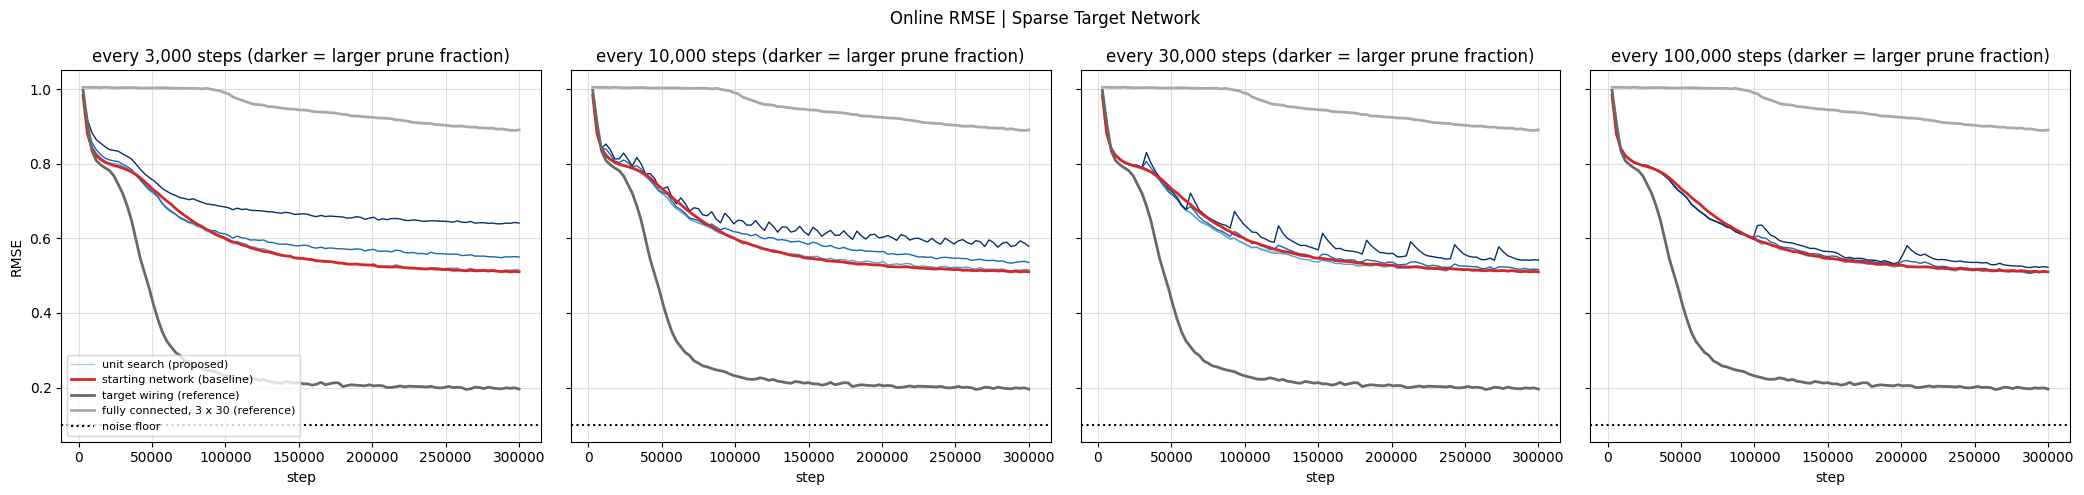

starting network (baseline)                   0.512
target wiring (reference)                     0.198
fully connected, 3 x 30 (reference)           0.893
unit search; rows: steps between structure changes; columns: prune fractions 0.05, 0.1, 0.3, 0.5
     3000: 0.515  0.514  0.551  0.641
    10000: 0.511  0.516  0.538  0.586
    30000: 0.513  0.511  0.520  0.550
   100000: 0.510  0.509  0.510  0.524


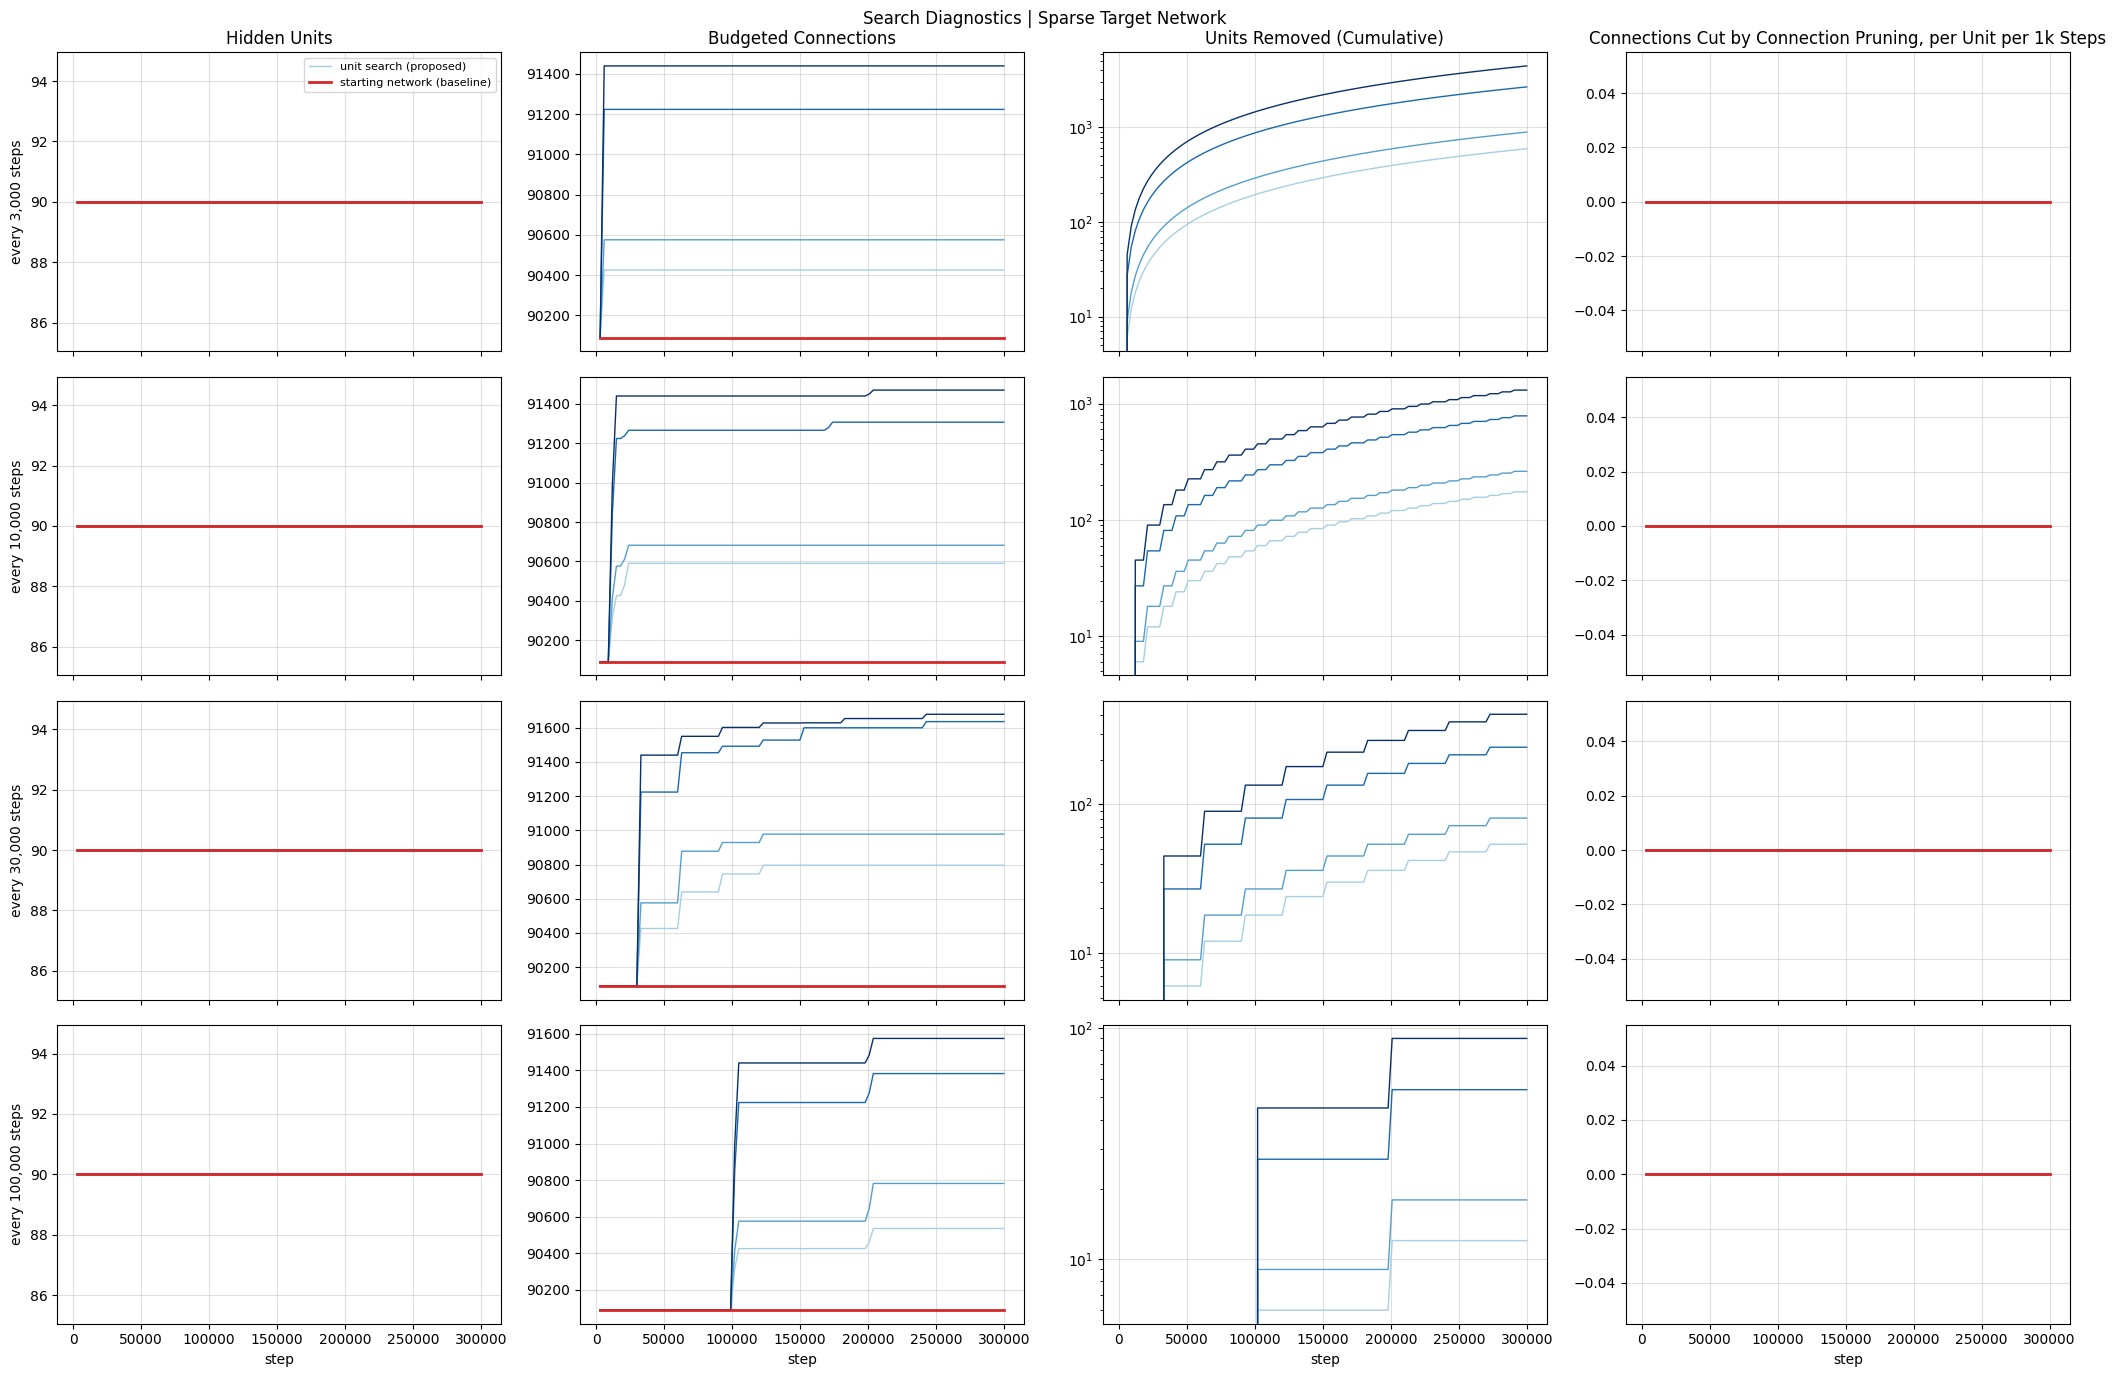

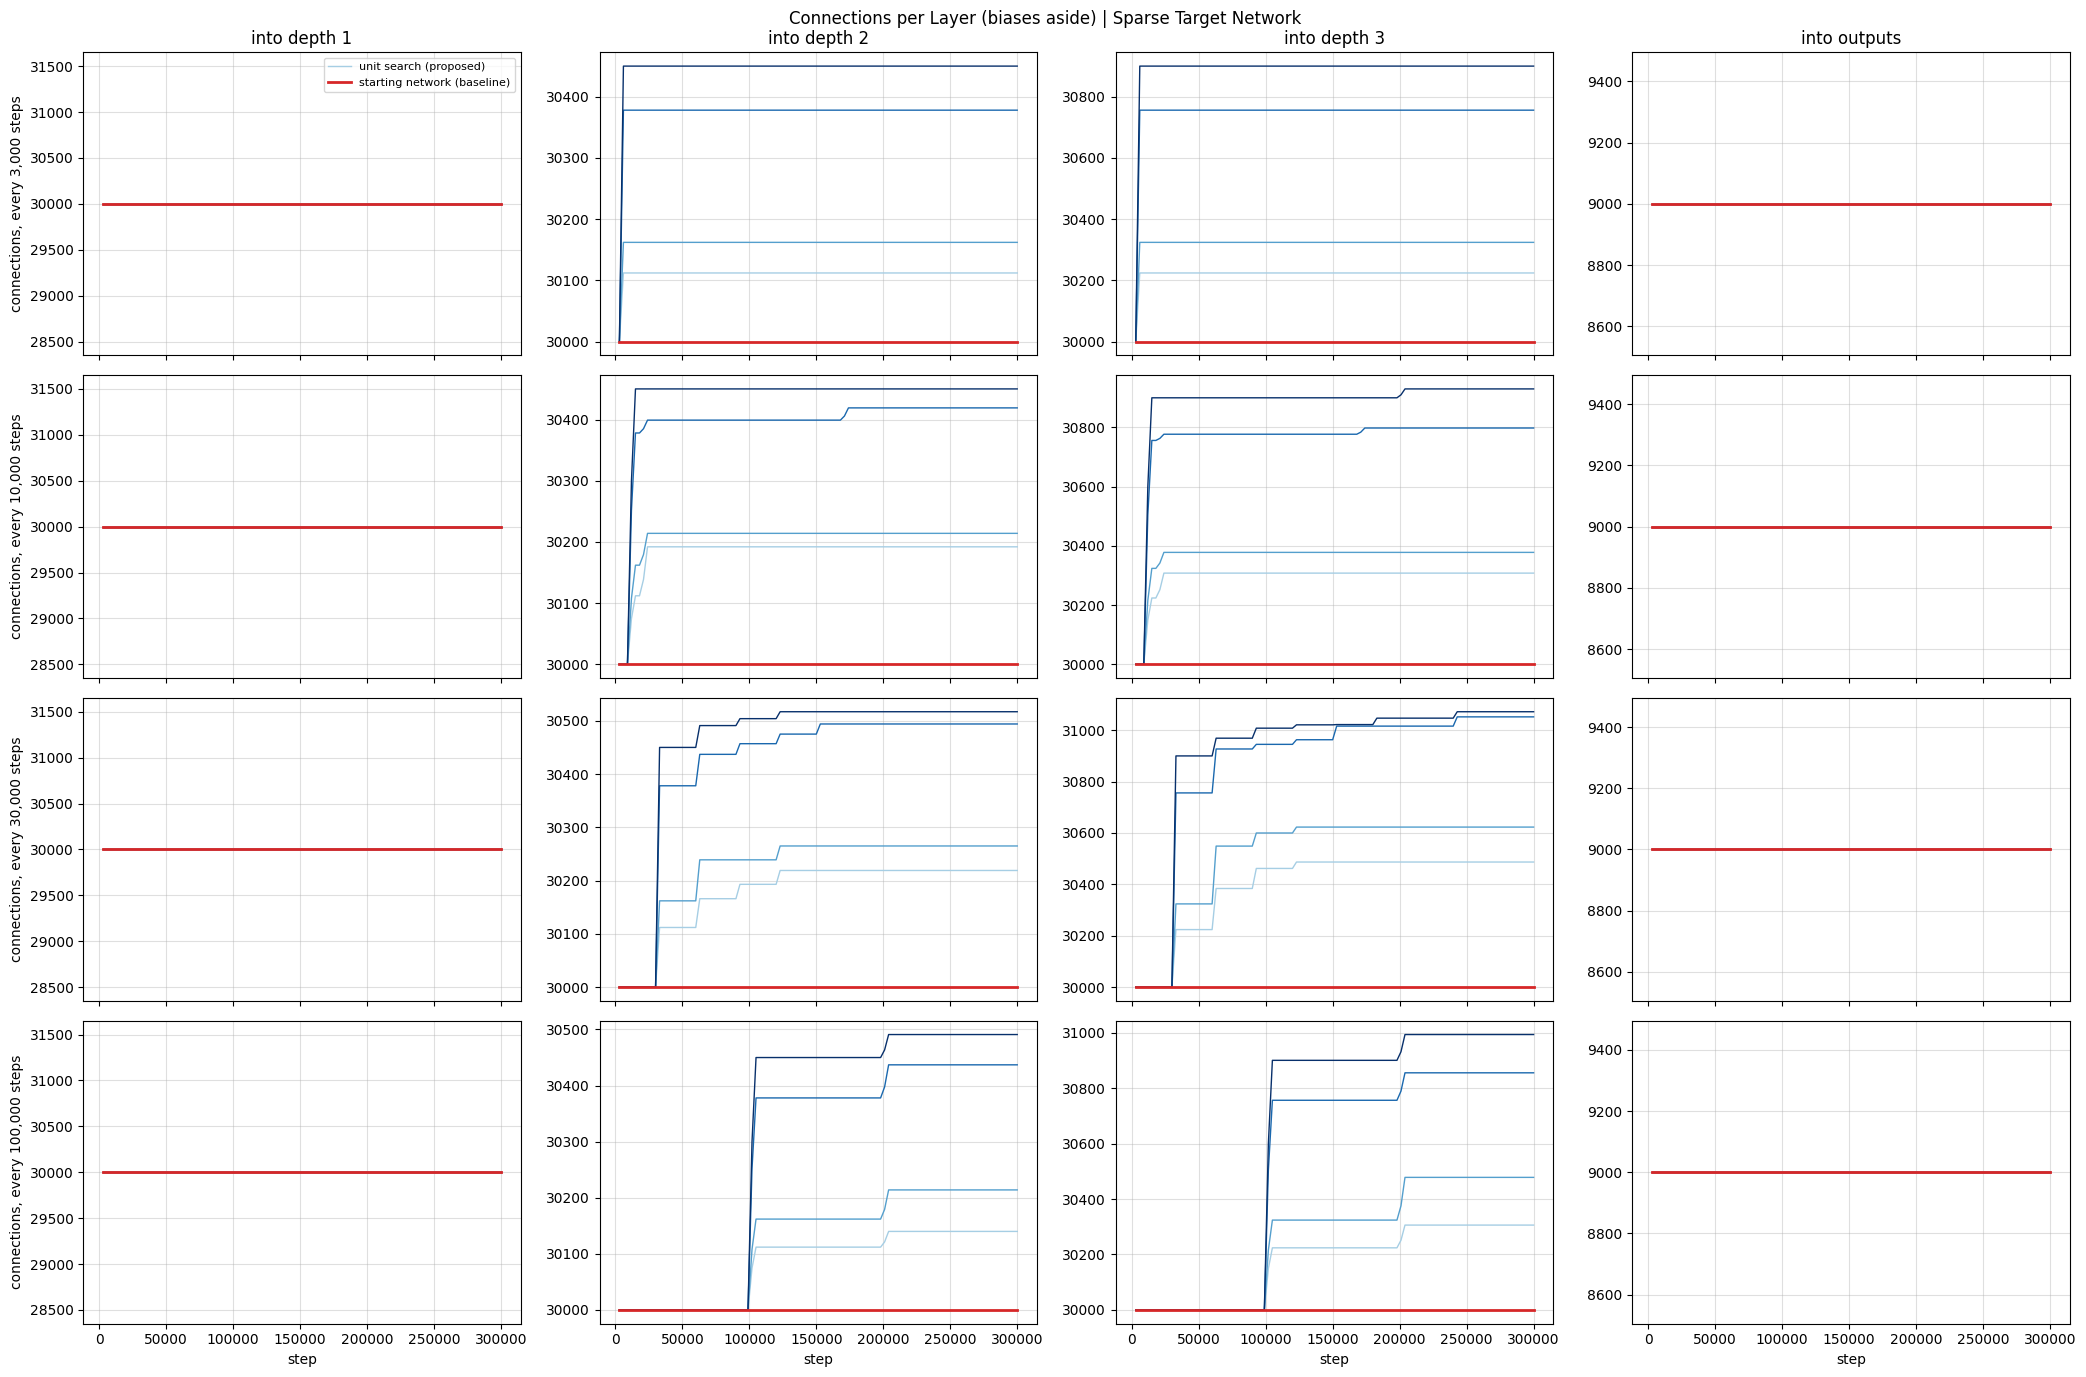

In [8]:
WINDOW = NUM_STEPS // N_WINDOWS
STEPS = (np.arange(N_WINDOWS) + 1) * WINDOW
final = lambda rmse: rmse[:, -round(N_WINDOWS * FINAL_FRACTION):].mean()
FRACTION_COLORS = dict(zip(PRUNE_FRACTIONS, plt.cm.Blues(np.linspace(0.35, 1.0, len(PRUNE_FRACTIONS)))))
OTHER_REFERENCES = {'target wiring (reference)': 'dimgray', f'fully connected, 3 x {START_UNITS} (reference)': 'darkgray'}


def curves(every, with_references=False):
    # (label, records, style) of each curve in the panels for one number of steps between structure changes: the unit
    # search runs, labeled once and colored by prune fraction; the starting network; and with_references, the other
    # references.
    runs = [c for c in SEARCH_CONFIGS if c.prune_every == every]
    out = [('unit search (proposed)' if i == 0 else None, searches[c], dict(color=FRACTION_COLORS[c.prune_fraction],
                                                                            lw=1)) for i, c in enumerate(runs)]
    out.append(('starting network (baseline)', references['starting network (baseline)'], dict(color='tab:red', lw=2)))
    if with_references:
        out += [(label, references[label], dict(color=color, lw=2)) for label, color in OTHER_REFERENCES.items()]
    return out


fig, axes = plt.subplots(1, len(PRUNE_EVERY), figsize=(21, 5), sharey=True)
for ax, every in zip(axes, PRUNE_EVERY):
    for label, res, style in curves(every, with_references=True):
        ax.plot(STEPS, res['rmse'].mean(0), label=label, **style)
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.set(xlabel='step', title=f'every {every:,} steps (darker = larger prune fraction)')
    ax.grid(alpha=0.4)
axes[0].set_ylabel('RMSE')
axes[0].legend(fontsize=8)
fig.suptitle('Online RMSE | Sparse Target Network')
fig.tight_layout()
plt.show()

for label, res in references.items():
    print(f'{label:<45} {final(res["rmse"]):.3f}')
print('unit search; rows: steps between structure changes; columns: prune fractions',
      ', '.join(f'{x:g}' for x in PRUNE_FRACTIONS))
for every in PRUNE_EVERY:
    print(f'  {every:>7}:', '  '.join(f'{final(searches[Config(every, x, 0.0, False)]["rmse"]):.3f}'
                                     for x in PRUNE_FRACTIONS))

fig, axes = plt.subplots(len(PRUNE_EVERY), 4, figsize=(21, 14), sharex=True)
for row, every in zip(axes, PRUNE_EVERY):
    for label, res, style in curves(every):
        row[0].plot(STEPS, res['units'].mean(0), label=label, **style)
        row[1].plot(STEPS, res['budgeted connections'].mean(0), **style)
        row[2].plot(STEPS, np.cumsum(res['removed'].mean(0) * WINDOW), **style)
        row[3].plot(STEPS, 1000 * res['cut per unit'].mean(0), **style)
    row[0].set_ylabel(f'every {every:,} steps')
    row[2].set_yscale('log')
    for ax in row:
        ax.grid(alpha=0.4)
for ax, title in zip(axes[0], ['Hidden Units', 'Budgeted Connections', 'Units Removed (Cumulative)',
                               'Connections Cut by Connection Pruning, per Unit per 1k Steps']):
    ax.set_title(title)
for ax in axes[-1]:
    ax.set_xlabel('step')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Search Diagnostics | Sparse Target Network')
fig.tight_layout()
plt.show()

LAYER_NAMES = [f'depth {d}' for d in range(1, N_DEPTHS + 1)] + ['outputs']
fig, axes = plt.subplots(len(PRUNE_EVERY), len(LAYER_NAMES), figsize=(21, 14), sharex=True)
for row, every in zip(axes, PRUNE_EVERY):
    for name, ax in zip(LAYER_NAMES, row):
        for label, res, style in curves(every):
            ax.plot(STEPS, res[f'connections into {name}'].mean(0), label=label, **style)
        ax.grid(alpha=0.4)
    row[0].set_ylabel(f'connections, every {every:,} steps')
for name, ax in zip(LAYER_NAMES, axes[0]):
    ax.set_title(f'into {name}')
for ax in axes[-1]:
    ax.set_xlabel('step')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Connections per Layer (biases aside) | Sparse Target Network')
fig.tight_layout()
plt.show()

## Results

300k steps, RMSE over the last 10% of training; unit search has 1 seed per configuration, everything else 5. The
notebook takes about 2 minutes.

- **Unit pruning does not beat the starting network.** Pruning a few units, or pruning rarely ($x \le$ 10%, or $n$ =
  100k), ends at 0.51, the same as the starting network left unchanged. Pruning more units more often is worse, up to
  0.64 at $x$ = 50% every 3k steps. Target wiring reaches 0.20, and the fully connected 3 × 30 network 0.89 (still
  improving).
- **The replacements only recover what pruning cost.** Each structure change raises the RMSE (clearest at $n$ = 30k and
  100k), and the new units bring it back to the starting network's curve, not below it. Without connection pruning, a
  new unit reads every input just as the unit it replaces did, so it is the same kind of unit, with a few hidden-unit
  inputs added: budgeted connections grow at most about 1.8%, from 90,090. Every depth stays at its 30 units.

5 runs in 22s
every layer reads all lower layers, 3 x 30 (reference)            0.453
fully connected, 3 x 30 (reference)                               0.893


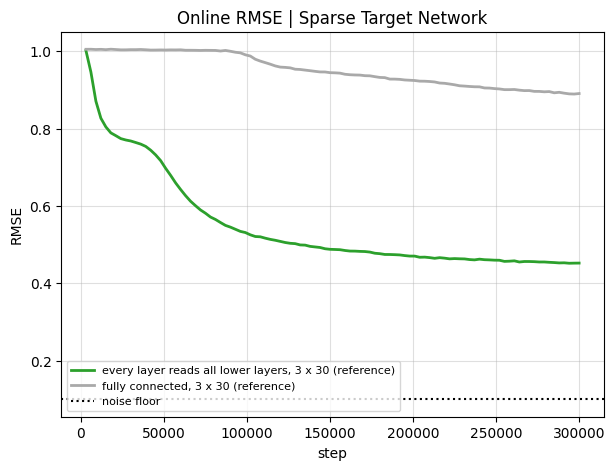

In [9]:
# Temporary: every unit reads every input and every unit of lower depths, and the outputs read every hidden unit (no
# shadow weights), against the fully connected reference, whose layers read only the layer below.
def all_lower_network(key):
    n = N_DEPTHS * SLOTS_PER_DEPTH
    depth = jnp.arange(n) // SLOTS_PER_DEPTH
    mask = {'hidden': jnp.concatenate([jnp.ones((n, N_INPUTS), bool), depth[None] < depth[:, None], jnp.ones((n, 1), bool)],
                                      axis=1),
            'output': jnp.ones((N_OUTPUTS, n + 1), bool)}
    return init_masked(key, mask, jnp.ones(n, bool))


all_lower = run_search(all_lower_network, [Config(NUM_STEPS, 0.0, 0.0, False)] * N_SEEDS, list(range(N_SEEDS)),
                       NUM_STEPS, fixed=True)
dense_label = f'fully connected, 3 x {START_UNITS} (reference)'
fig, ax = plt.subplots(figsize=(7, 5))
for label, res, color in [(f'every layer reads all lower layers, 3 x {START_UNITS} (reference)', all_lower, 'tab:green'),
                          (dense_label, references[dense_label], 'darkgray')]:
    ax.plot(STEPS, res['rmse'].mean(0), label=label, color=color, lw=2)
    print(f'{label:<65} {final(res["rmse"]):.3f}')
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set(xlabel='step', ylabel='RMSE', title='Online RMSE | Sparse Target Network')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()